# Multi-run real-data RBF kernel fit

The latest fit shares ARD RBF length scales, signal variance and measurement noise across traversals. The exact Gaussian likelihood uses independent traversal blocks, with a separate constant mean fitted for each run. The parameters were optimized with L-BFGS-B from three starting points and selected by training likelihood. The formal export uses all available traversals, including 21 November.

In [1]:
current_run_name = 'multirun_fit_20261127T025820Z'
from pathlib import Path
import csv
import hashlib
import html
import json
from IPython.display import display, HTML

result_root = Path.cwd() / "result"
current_run = result_root / current_run_name
current_hp = json.loads((current_run / "hyperparameters.json").read_text())
current_summary = json.loads((current_run / "training_summary.json").read_text())
current_manifest = json.loads((current_run / "manifest.json").read_text())
legacy_name = json.loads((result_root / "latest.json").read_text())["run"]
legacy_hp = json.loads((result_root / legacy_name / "hyperparameters.json").read_text())

def report_table(headers, rows):
    def wrap(row, cell):
        return "<tr>" + "".join(f"<{cell}>{html.escape(str(value))}</{cell}>" for value in row) + "</tr>"
    display(HTML("<table>" + wrap(headers, "th") + "".join(wrap(row, "td") for row in rows) + "</table>"))

report_table(["Training date", "Matched measurements", "Fitted run mean (deg C)"],
             [[date, count, f"{current_summary['fitted_run_means_c'][date]:.3f}"]
              for date, count in current_summary["observations_by_date"].items()])
labels = ["East length scale (m)", "North length scale (m)", "Time length scale (s)",
          "Signal variance (deg C squared)", "Measurement noise variance (deg C squared)",
          "Measurement noise SD (deg C)"]
def values(p):
    return [*p["lengthscales_m_m_s"], p["output_variance_c2"], p["noise_variance_c2"], p["noise_std_c"]]
report_table(["Parameter", "Multi-run fit", "Archived single-run fit"],
             [[label, f"{current:.7g}", f"{old:.7g}"]
              for label, current, old in zip(labels, values(current_hp), values(legacy_hp))])
for filename, digest in current_manifest["output_sha256"].items():
    assert hashlib.sha256((current_run / filename).read_bytes()).hexdigest() == digest
assert sum(current_summary["observations_by_date"].values()) == current_hp["training_observations"]
reserved_date = current_hp["reserved_validation_date"]
assert reserved_date is None or reserved_date not in current_hp["training_dates"]
print(f"Training observations: {current_hp['training_observations']:,}")
print(f"Reserved validation run: {reserved_date}" if reserved_date else "All six traversals are in the fit.")
print(f"Kernel export: result/{current_run_name}/hyperparameters.json")

Training date,Matched measurements,Fitted run mean (deg C)
2026-11-03,980,27.280
2026-11-17,1360,16.702
2026-11-18,24,20.117
2026-11-19,1365,22.771
2026-11-20,1358,16.392
2026-11-21,1361,10.821


Parameter,Multi-run fit,Archived single-run fit
East length scale (m),6.247029,3.59815
North length scale (m),44.10294,21.09391
Time length scale (s),37.93368,21.13564
Signal variance (deg C squared),0.47981,0.05897603
Measurement noise variance (deg C squared),0.0008420944,0.0008652817
Measurement noise SD (deg C),0.02901886,0.02941567


Training observations: 6,448
All six traversals are in the fit.
Kernel export: result/multirun_fit_20261127T025820Z/hyperparameters.json


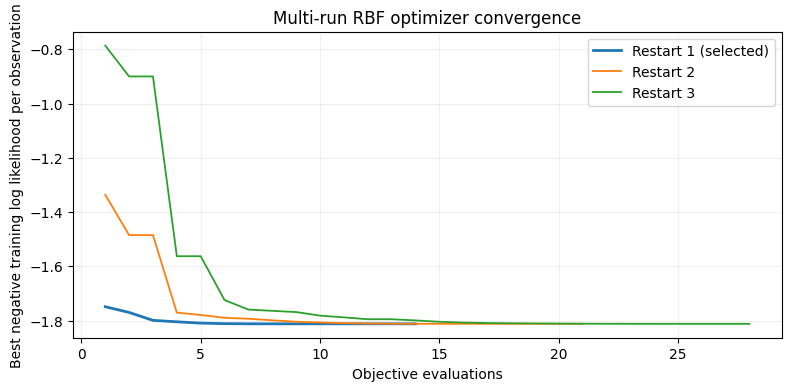

Restart,Converged,Iterations,Final loss per observation
1,True,13,-1.811970393
2,True,17,-1.811970393
3,True,23,-1.811970393


In [2]:
import matplotlib.pyplot as plt
import numpy as np

with (current_run / "training_history.csv").open(newline="", encoding="utf-8") as f:
    evaluations = list(csv.DictReader(f))
with (current_run / "initialization_comparison.csv").open(newline="", encoding="utf-8") as f:
    attempts = list(csv.DictReader(f))

fig, ax = plt.subplots(figsize=(7.8, 3.8), layout="constrained")
for attempt in attempts:
    restart = attempt["restart"]
    rows = [row for row in evaluations if row["restart"] == restart]
    evaluations_used = [int(row["evaluation"]) for row in rows]
    losses = [float(row["negative_mll_per_observation"]) for row in rows]
    selected = int(restart) == current_hp["selected_restart"]
    ax.plot(evaluations_used, np.minimum.accumulate(losses),
            linewidth=2 if selected else 1.3,
            label=f"Restart {restart}" + (" (selected)" if selected else ""))
ax.set(xlabel="Objective evaluations", ylabel="Best negative training log likelihood per observation",
       title="Multi-run RBF optimizer convergence")
ax.grid(alpha=0.2)
ax.legend()
plt.show()

report_table(["Restart", "Converged", "Iterations", "Final loss per observation"],
             [[r["restart"], r["converged"], r["iterations"], f"{float(r['negative_mll_per_observation']):.9f}"]
              for r in attempts])

## Interpretation

The parameter table compares two different training datasets and fitting setups. The optimizer curve describes convergence on the training observations. The all-data fit has no independent real-data accuracy score. The formal simulation imports the trained length scales, signal variance and measurement noise variance. It initializes the GP with zero observations and a fixed prior mean of 25 deg C.

# Archived single-run RBF kernel fit

Fit one reusable spatiotemporal GP to **all 980 aligned observations**. Clock synchronization with zero additional offset is accepted as an experimental assumption. This full-data model is stored separately from the minimal-test models. There is no independent test set for this fit.

The [README](README.md) describes the source data, exact units, dependencies and model-loading example.

In [3]:
from pathlib import Path
import json, hashlib, html
from IPython.display import display, HTML, Image
root=Path.cwd()
run=root/'result'/json.loads((root/'result'/'latest.json').read_text())['run']
hp=json.loads((run/'hyperparameters.json').read_text())
rows=[['East lengthscale (m)',hp['lengthscales_m_m_s'][0]],
      ['North lengthscale (m)',hp['lengthscales_m_m_s'][1]],
      ['Time lengthscale (s)',hp['lengthscales_m_m_s'][2]],
      ['Signal variance (°C²)',hp['output_variance_c2']],
      ['Observation-noise variance (°C²)',hp['noise_variance_c2']],
      ['Observation-noise SD (°C)',hp['noise_std_c']],
      ['Learned mean (°C)',hp['mean_c']],['Training observations',hp['training_observations']]]
display(HTML('<table><tr><th>Parameter</th><th>Value</th></tr>'+''.join(
    '<tr><td>'+html.escape(k)+'</td><td>'+str(round(v,6))+'</td></tr>' for k,v in rows)+'</table>'))
print('Model:',run/'spatiotemporal_gp.pt')
print('Kernel: ConstantMean + ScaleKernel(RBF_ARD_xy × RBF_t), Gaussian likelihood')

Parameter,Value
East lengthscale (m),3.59815
North lengthscale (m),21.093915
Time lengthscale (s),21.135643
Signal variance (°C²),0.058976
Observation-noise variance (°C²),0.000865
Observation-noise SD (°C),0.029416
Learned mean (°C),27.152507
Training observations,980


Model: C:\Users\Administrator\Documents\4RP3\Code\4RP3_Simulation\Trained_Kernel\result\full_fit_20261105T031701003839Z\spatiotemporal_gp.pt
Kernel: ConstantMean + ScaleKernel(RBF_ARD_xy × RBF_t), Gaussian likelihood


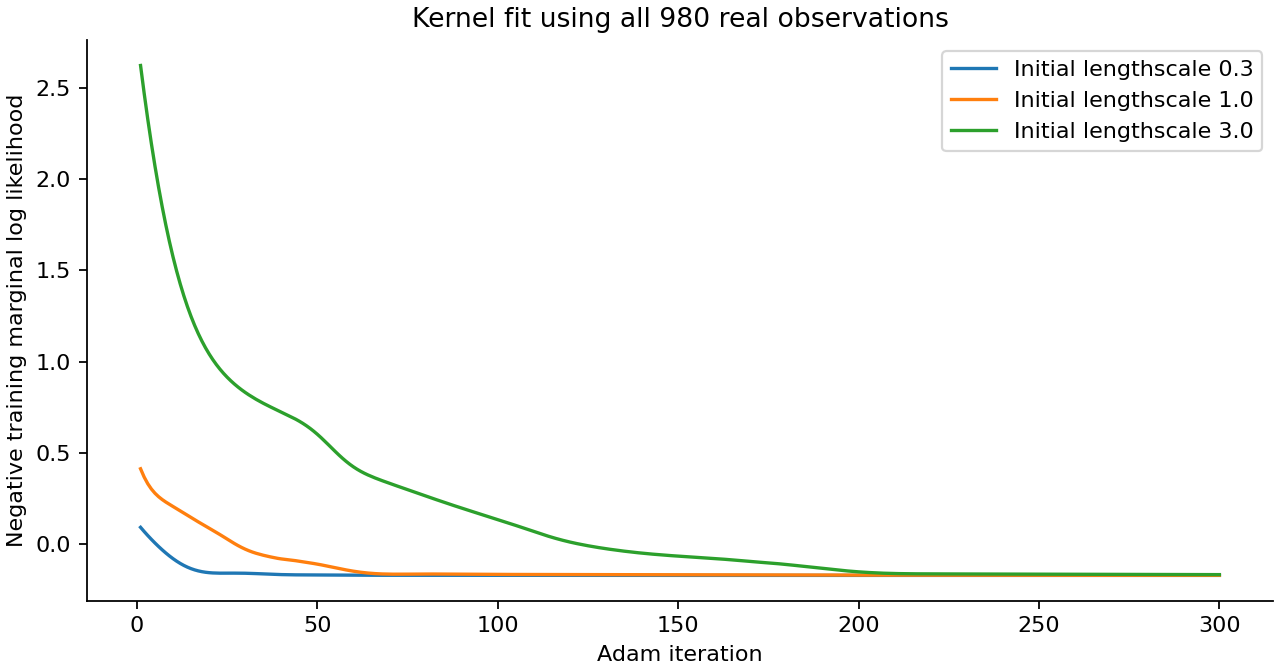

In [4]:
display(Image(filename=str(root/'result'/'figures'/'full_data_training.png'),embed=True))

## Verification and interpretation

The initialization is selected using training marginal likelihood. These curves measure training optimization, not held-out accuracy. The checkpoint includes the fitted kernel, all training observations and the scaler. Original coordinate and time references must be retained when querying it.

In [5]:
manifest=json.loads((run/'manifest.json').read_text())
for name,expected in manifest['outputs'].items():
    assert hashlib.sha256((run/name).read_bytes()).hexdigest()==expected,name
assert hashlib.sha256((run/'input_samples.csv').read_bytes()).hexdigest()==manifest['input_sha256']
assert hashlib.sha256((root/'testing_code'/'gp_model.py').read_bytes()).hexdigest()==manifest['gp_model_sha256']
v=json.loads((run/'verification.json').read_text()); assert v['passed']
print(len(v['checks']),'numerical/data checks passed. Saved model and loader hashes match.')
print('The worker checked reload predictions and independent NumPy/SciPy RBF/Cholesky calculations.')
print('This full-data fit has no independent accuracy estimate; previous test scores remain separate.')

13 numerical/data checks passed. Saved model and loader hashes match.
The worker checked reload predictions and independent NumPy/SciPy RBF/Cholesky calculations.
This full-data fit has no independent accuracy estimate; previous test scores remain separate.


## Result

The full-data kernel and conditioned GP are saved and loadable. They can be used for the next stage under the recorded experimental assumptions. Fit completion does not establish long-horizon accuracy or unique separation of spatial and temporal structure from one mobile run. Keep any new validation observations separate from these training data.